<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">Datos Masivos II · PRÁCTICA 3</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">Red de colaboraciones de Spotify: PageRank, HITS y PageRank sensible a tópico</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Equipo Tres: Castrillo Cruz Karen Arlet, Ramos González Nadia, Zamora Antiga Ángel Javier.</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

## Instrucciones
Utiliza los diferentes dataset y analízalo utilizando HITS, PageRank y Sensible a tópico.

<div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">0. Contexto. Red de colaboraciones entre artistas de Spotify</span></div>

Se trabajará con el conjunto de datos *Spotify Artist Feature Collaboration Network* ([Kaggle](https://www.kaggle.com/datasets/jfreyberg/spotify-artist-feature-collaboration-network)), construido con la API de Spotify. Cada nodo es un artista y cada arista indica que dos artistas aparecen juntos en al menos una canción (un *featuring* o colaboración).

Una red de este tipo permite preguntarse quiénes son los artistas *centrales* de la industria, más allá de su número de seguidores: un artista que colabora con muchos otros artistas, que a su vez son centrales, ocupa una posición estructural relevante. Para medirlo usaremos tres algoritmos de análisis de enlaces:

* **PageRank:** importancia global de un nodo según la probabilidad estacionaria de un caminante aleatorio con teletransportación.
* **HITS:** separa la importancia en dos papeles, *hubs* (nodos que apuntan a buenas autoridades) y *autoridades* (nodos apuntados por buenos hubs).
* **PageRank sensible a tópico:** PageRank cuya teletransportación se restringe a los nodos de un tema, en nuestro caso, a artistas de un mismo macrogénero musical.

<div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">0.1 Los Datos </span></div>

Se cuenta con dos archivos `.csv`:

| Archivo | Registros | Columnas |
| :--- | :--- | :--- |
| `nodes.csv` | 156,422 artistas | `spotify_id`, `name`, `followers`, `popularity`, `genres`, `chart_hits` |
| `edges.csv` | 300,386 colaboraciones | `id_0`, `id_1` |

* `followers`: número de seguidores del artista en Spotify.
* `popularity`: índice de popularidad de Spotify, de 0 a 100.
* `genres`: lista de géneros asignados por Spotify al artista.
* `chart_hits`: lista de países en cuyos *charts* apareció el artista, con el número de apariciones.

Las aristas no tienen dirección ni peso: una colaboración entre `id_0` e `id_1` es simétrica.

<div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">0.2 Preparación de Entorno  </span></div>

In [1]:
# Manejo de datos
import ast
import numpy as np
import pandas as pd
from collections import Counter

# Grafos y álgebra dispersa
import scipy.sparse as sp
from scipy.sparse.csgraph import connected_components
from scipy.sparse.linalg import eigsh
import networkx as nx

# Estadística
from scipy.stats import spearmanr

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
nodos = pd.read_csv('Datos/nodes.csv')
aristas = pd.read_csv('Datos/edges.csv')

print(f'Nodos (artistas): {nodos.shape}')
print(f'Aristas (colaboraciones): {aristas.shape}')
print('Muestra de nodos:')
display(nodos.head())
print('Muestra de aristas:')
display(aristas.head())

Nodos (artistas): (156422, 6)
Aristas (colaboraciones): (300386, 2)
Muestra de nodos:


,spotify_id,name,followers,popularity,genres,chart_hits
0,48WvrUGoijadXXCsGocwM4,Byklubben,1738.0,24,"['nordic house', 'russelater']",['no (3)']
1,4lDiJcOJ2GLCK6p9q5BgfK,Kontra K,1999676.0,72,"['christlicher rap', 'german hip hop']","['at (44)', 'de (111)', 'lu (22)', 'ch (31)', ..."
2,652XIvIBNGg3C0KIGEJWit,Maxim,34596.0,36,[],['de (1)']
3,3dXC1YPbnQPsfHPVkm1ipj,Christopher Martin,249233.0,52,"['dancehall', 'lovers rock', 'modern reggae', ...","['at (1)', 'de (1)']"
4,74terC9ol9zMo8rfzhSOiG,Jakob Hellman,21193.0,39,"['classic swedish pop', 'norrbotten indie', 's...",['se (6)']


Muestra de aristas:


,id_0,id_1
0,76M2Ekj8bG8W7X2nbx2CpF,7sfl4Xt5KmfyDs2T3SVSMK
1,0hk4xVujcyOr6USD95wcWb,7Do8se3ZoaVqUt3woqqSrD
2,38jpuy3yt3QIxQ8Fn1HTeJ,4csQIMQm6vI2A2SCVDuM2z
3,6PvcxssrQ0QaJVaBWHD07l,6UCQYrcJ6wab6gnQ89OJFh
4,2R1QrQqWuw3IjoP5dXRFjt,4mk1ScvOUkuQzzCZpT6bc0


<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">1. Selección de datos</span></div>

Antes de construir el grafo revisamos la consistencia entre ambos archivos: identificadores repetidos, valores nulos, aristas que apunten a artistas inexistentes, lazos y aristas repetidas.

In [3]:
ids_nodos = set(nodos['spotify_id'])
pares_ordenados = pd.DataFrame(np.sort(aristas[['id_0', 'id_1']].values, axis=1))

calidad = pd.Series({
    'IDs repetidos en nodes.csv': nodos['spotify_id'].duplicated().sum(),
    'Filas completamente idénticas': nodos.duplicated().sum(),
    'Artistas sin nombre': nodos['name'].isna().sum(),
    'Artistas sin seguidores': nodos['followers'].isna().sum(),
    'Artistas sin géneros (lista vacía)': (nodos['genres'] == '[]').sum(),
    'Artistas sin chart_hits': nodos['chart_hits'].isna().sum(),
    'Aristas con un extremo inexistente': (~aristas['id_0'].isin(ids_nodos) | ~aristas['id_1'].isin(ids_nodos)).sum(),
    'Lazos (artista consigo mismo)': (aristas['id_0'] == aristas['id_1']).sum(),
    'Aristas repetidas (sin dirección)': pares_ordenados.duplicated().sum(),
}, name='Conteo')
display(calidad.to_frame())

,Conteo
IDs repetidos en nodes.csv,102
Filas completamente idénticas,0
Artistas sin nombre,4
Artistas sin seguidores,4
Artistas sin géneros (lista vacía),102133
Artistas sin chart_hits,136781
Aristas con un extremo inexistente,7
Lazos (artista consigo mismo),0
Aristas repetidas (sin dirección),0


In [4]:
duplicados = nodos[nodos['spotify_id'].duplicated(keep=False)].sort_values('spotify_id')
display(duplicados.head(10))

,spotify_id,name,followers,popularity,genres,chart_hits
8724,008PpLcKUtVXle6JSwkq3I,Emiway Bantai,948.0,61,"['desi hip hop', 'desi pop', 'desi trap', 'hin...",['in (3)']
8996,008PpLcKUtVXle6JSwkq3I,Emiway Bantai,2388678.0,61,"['desi hip hop', 'desi pop', 'desi trap', 'hin...",['in (3)']
1332,06nxKVMna7BWGFlAREsPDh,Ieva Narkutė,0.0,28,"['dainuojamoji poezija', 'lithuanian pop', 'su...",['lt (1)']
9309,06nxKVMna7BWGFlAREsPDh,Ieva Narkutė,7313.0,28,"['dainuojamoji poezija', 'lithuanian pop', 'su...",['lt (1)']
16843,07h4CCFmlXkwx0g4PL5Uuh,Guy2bezbar,188126.0,63,"['french hip hop', 'pop urbaine', 'rap francais']","['be (1)', 'fr (13)']"
18500,07h4CCFmlXkwx0g4PL5Uuh,Guy2bezbar,0.0,63,"['french hip hop', 'pop urbaine', 'rap francais']","['be (1)', 'fr (13)']"
11855,09Dl9cjeo9oXfJfMuuQCp1,Lucerina,39.0,45,['new school turkce rap'],"['cy (1)', 'tr (1)']"
15908,09Dl9cjeo9oXfJfMuuQCp1,Lucerina,26906.0,43,['new school turkce rap'],"['cy (1)', 'tr (1)']"
9636,0UeKDbiaApyP7qKfcmGN03,Lesram,17496.0,48,"['french hip hop', 'pop urbaine', 'rap conscie...",['fr (2)']
18068,0UeKDbiaApyP7qKfcmGN03,Lesram,0.0,48,"['french hip hop', 'pop urbaine', 'rap conscie...",['fr (2)']


### **Observaciones iniciales**

Los 102 IDs repetidos corresponden al mismo artista: coinciden el nombre, los géneros y los *charts*, pero uno de los dos registros tiene un número de seguidores nulo o mucho menor. Lo más probable es que se trate de dos descargas del mismo perfil en momentos distintos, una de ellas incompleta. Conservaremos el registro con más seguidores.

Las 7 aristas con un extremo inexistente no pueden ubicarse en la red, por lo que se descartan. No hay lazos ni aristas repetidas, así que el grafo es simple. Los valores nulos de `genres` y `chart_hits` no son errores: indican que Spotify no asignó género al artista o que este nunca apareció en un *chart*.

Además de los problemas anteriores, existen *seudoartistas*: créditos genéricos como `Traditional` o `Anonymous`, que Spotify usa cuando la obra no tiene un autor identificable. No representan a un artista real y conectan obras sin relación entre sí, así que los revisamos antes de decidir si se eliminan.

In [5]:
grado_previo = pd.concat([aristas['id_0'], aristas['id_1']]).value_counts()
seudoartistas = ['Traditional', 'Trad.', 'Anonymous', 'Unknown', 'Unknown Artist', 'Various Artists']

revision = nodos[nodos['name'].isin(seudoartistas)].copy()
revision['colaboraciones'] = revision['spotify_id'].map(grado_previo).fillna(0).astype(int)
display(revision[['spotify_id', 'name', 'followers', 'popularity', 'colaboraciones']])

,spotify_id,name,followers,popularity,colaboraciones
9812,0LyfQWJT6nXafLPZqxe9Of,Various Artists,1540234.0,0,17
10101,2mv12nN6hV35GVNKdvyEM9,Various Artists,1083.0,41,1
18735,1U5zgr455OGyIkLNXvDdrf,Traditional,49046.0,59,1371
19822,70XDQznwvvFLK2HZrI7Cau,Unknown,63.0,33,2
23193,2MpxaqGTQeft5RU4wvwm57,Unknown,9779.0,41,8
43838,4gqPenZXmxCQR1hGUNvvQE,Trad.,33.0,23,3
63302,38eegpxNtQuMSIZUiby2O8,Anonymous,77.0,33,3
95764,3cUqbKwZNSvGlW9Bffetc4,Trad.,0.0,0,1
105930,74Ch11L4833kZ9VfyziR3K,Unknown Artist,3061.0,39,3
116292,4kCZ5nyurc9eIqLJfUcW0Y,Anonymous,14056.0,53,8


`Traditional` acumula 1,371 colaboraciones: sería el segundo artista con más colaboradores de la red, aunque solo es el crédito de las canciones de autor desconocido (villancicos, canciones folclóricas, etcétera). Mantenerlo crearía un nodo central artificial que conecta a intérpretes sin relación entre sí. El resto de los seudoartistas tiene pocas colaboraciones, pero se eliminan por el mismo criterio.

In [6]:
n_original, m_original = len(nodos), len(aristas)

# Por cada ID repetido, conservamos el registro con más seguidores
nodos = (nodos.sort_values('followers', ascending=False).drop_duplicates('spotify_id').reset_index(drop=True))

# Eliminamos los seudoartistas
nodos = nodos[~nodos['name'].isin(seudoartistas)]

# Conservamos solo las aristas cuyos dos extremos existen
aristas = aristas[aristas['id_0'].isin(nodos['spotify_id']) & aristas['id_1'].isin(nodos['spotify_id'])].reset_index(drop=True)

# Eliminamos los artistas sin colaboraciones (nodos aislados)
activos = pd.unique(pd.concat([aristas['id_0'], aristas['id_1']]))
print(f'Artistas aislados eliminados: {(~nodos["spotify_id"].isin(activos)).sum()}')
nodos = nodos[nodos['spotify_id'].isin(activos)].reset_index(drop=True)

# Nombres faltantes: se usa el ID para poder identificarlos en las tablas
nodos['name'] = nodos['name'].fillna(nodos['spotify_id'])

print(f'Artistas eliminados: {n_original - len(nodos)}')
print(f'Colaboraciones eliminadas: {m_original - len(aristas)}')

Artistas aislados eliminados: 4153
Artistas eliminados: 4265
Colaboraciones eliminadas: 1419


Las columnas `genres` y `chart_hits` están almacenadas como texto. Las convertimos a listas y diccionarios de Python, y derivamos algunas variables de apoyo para el análisis exploratorio.

In [7]:
nodos['genres'] = nodos['genres'].map(ast.literal_eval)
nodos['chart_hits'] = (nodos['chart_hits'].fillna('[]').map(ast.literal_eval).map(lambda l: {h.split(' (')[0]: int(h.split(' (')[1].rstrip(')')) for h in l}))

nodos['n_generos'] = nodos['genres'].str.len()
nodos['n_paises_chart'] = nodos['chart_hits'].str.len()
nodos['grado'] = nodos['spotify_id'].map(pd.concat([aristas['id_0'], aristas['id_1']]).value_counts())

display(nodos.head())

,spotify_id,name,followers,popularity,genres,chart_hits,n_generos,n_paises_chart,grado
0,6eUKZXaKkcviH0Ku9w2n3V,Ed Sheeran,102156853.0,90,"[pop, uk pop]","{'us': 52, 'gb': 83, 'ar': 36, 'au': 65, 'at':...",2,71,153
1,66CXWjxzNUsdJxJ2JdwvnR,Ariana Grande,83045090.0,88,"[dance pop, pop]","{'us': 81, 'gb': 69, 'ar': 36, 'au': 70, 'at':...",2,71,69
2,6qqNVTkY8uBg9cP3Jd7DAH,Billie Eilish,68407227.0,88,"[art pop, electropop, pop]","{'us': 46, 'gb': 43, 'ar': 23, 'au': 45, 'at':...",3,71,14
3,3TVXtAsR1Inumwj472S9r4,Drake,66852536.0,95,"[canadian hip hop, canadian pop, hip hop, rap,...","{'us': 190, 'gb': 163, 'ar': 18, 'au': 148, 'a...",5,71,111
4,1uNFoZAHBGtllmzznpCI3s,Justin Bieber,65590075.0,90,"[canadian pop, pop]","{'us': 58, 'gb': 51, 'ar': 29, 'au': 54, 'at':...",2,71,114


<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">2. Análisis Exploratorio </span></div>

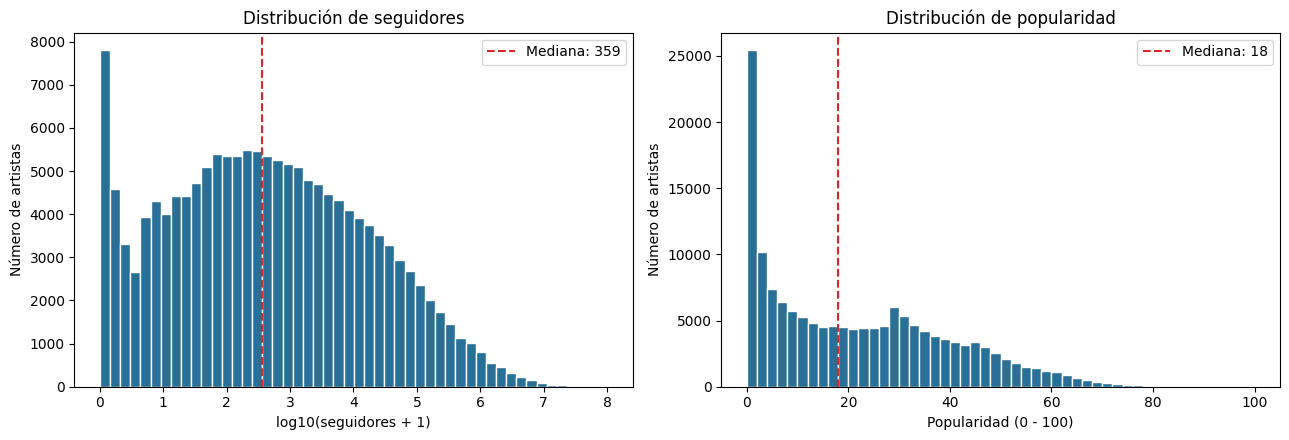

,count,mean,std,min,25%,50%,75%,max
followers,152153.0,86031.428063,942128.204558,0.0,24.0,359.0,6236.0,102156853.0
popularity,152157.0,21.259863,18.293894,0.0,4.0,18.0,34.0,100.0


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

seguidores = nodos['followers'].dropna()
axes[0].hist(np.log10(seguidores + 1), bins=50, color='#2a6f97', edgecolor='white')
axes[0].axvline(np.log10(seguidores.median() + 1), color='#d62828', ls='--', label=f'Mediana: {seguidores.median():,.0f}')
axes[0].set_xlabel('log10(seguidores + 1)')
axes[0].set_ylabel('Número de artistas')
axes[0].set_title('Distribución de seguidores')
axes[0].legend()

axes[1].hist(nodos['popularity'], bins=50, color='#2a6f97', edgecolor='white')
axes[1].axvline(nodos['popularity'].median(), color='#d62828', ls='--', label=f'Mediana: {nodos["popularity"].median():.0f}')
axes[1].set_xlabel('Popularidad (0 - 100)')
axes[1].set_ylabel('Número de artistas')
axes[1].set_title('Distribución de popularidad')
axes[1].legend()

fig.tight_layout()
plt.show()

display(nodos[['followers', 'popularity']].describe().T)

Los seguidores abarcan ocho órdenes de magnitud: la mediana es de apenas 359, mientras que la media supera los 86 mil, arrastrada por unos cuantos artistas globales (Ed Sheeran rebasa los 100 millones). Por ello se grafican en escala logarítmica. La popularidad también está sesgada a la derecha (mediana 18) y presenta una acumulación en 0, típica de artistas con muy pocas reproducciones recientes.

Como ambas variables son tan asimétricas, en lo sucesivo las compararemos con los algoritmos mediante la correlación de Spearman, que solo considera el orden.

Géneros distintos: 4,799
Artistas sin ningún género: 65.4%


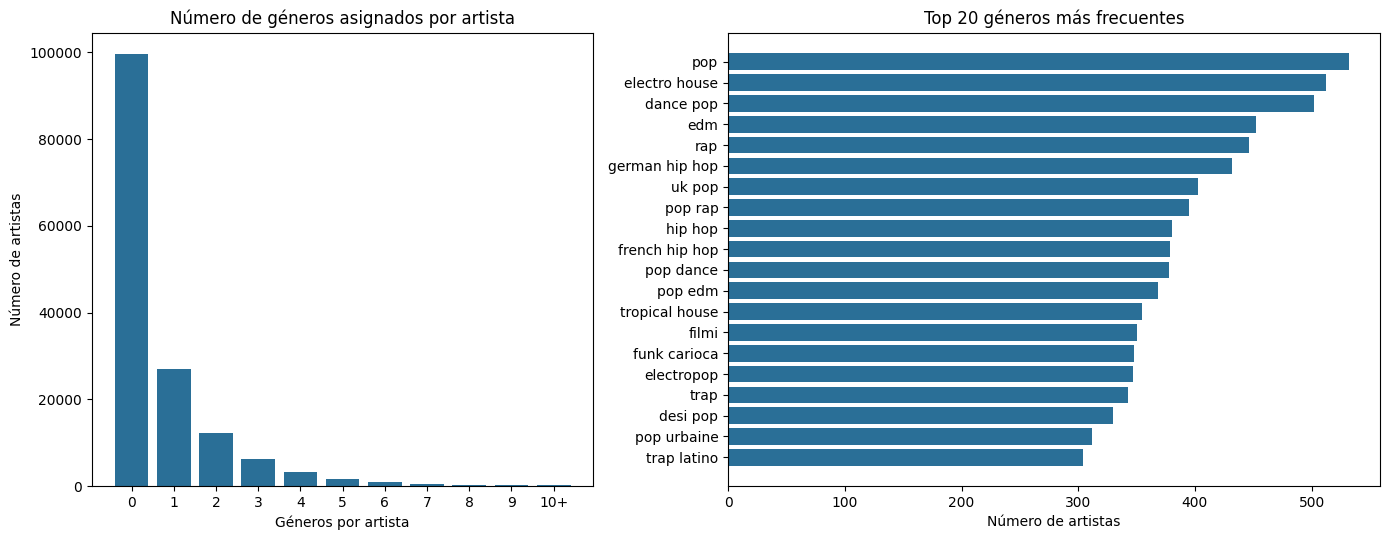

In [9]:
conteo_generos = Counter(g for lista in nodos['genres'] for g in lista)
print(f'Géneros distintos: {len(conteo_generos):,}')
print(f'Artistas sin ningún género: {(nodos["n_generos"] == 0).mean():.1%}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [1, 1.3]})

distribucion = nodos['n_generos'].clip(upper=10).value_counts().sort_index()
axes[0].bar([str(i) if i < 10 else '10+' for i in distribucion.index], distribucion.values, color='#2a6f97')
axes[0].set_xlabel('Géneros por artista')
axes[0].set_ylabel('Número de artistas')
axes[0].set_title('Número de géneros asignados por artista')

top = conteo_generos.most_common(20)[::-1]
axes[1].barh([g for g, _ in top], [c for _, c in top], color='#2a6f97')
axes[1].set_xlabel('Número de artistas')
axes[1].set_title('Top 20 géneros más frecuentes')

fig.tight_layout()
plt.show()

El 65.4% de los artistas no tiene ningún género asignado, y el resto se reparte entre 4,799 etiquetas distintas. Además, muchas de las etiquetas más frecuentes son variantes regionales de un mismo estilo, como pop. Con tantas etiquetas, cada una agruparía a muy pocos artistas para servir como tópico, lo que justifica agruparlas en macrogéneros durante la transformación.

Artistas con al menos una aparición en charts: 10.9%


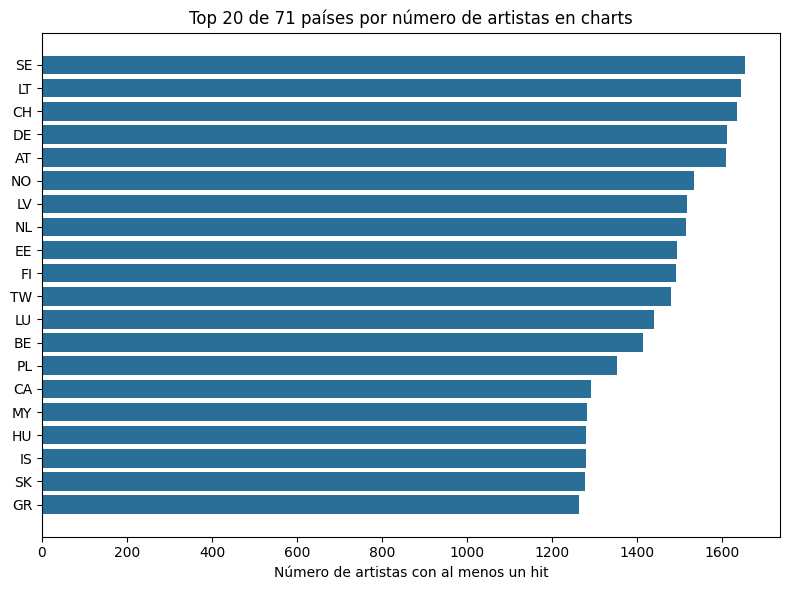

In [10]:
con_chart = nodos['n_paises_chart'] > 0
print(f'Artistas con al menos una aparición en charts: {con_chart.mean():.1%}')

artistas_por_pais = Counter(p for d in nodos['chart_hits'] for p in d)
top = artistas_por_pais.most_common(20)[::-1]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh([p.upper() for p, _ in top], [c for _, c in top], color='#2a6f97')
ax.set_xlabel('Número de artistas con al menos un hit')
ax.set_title(f'Top 20 de {len(artistas_por_pais)} países por número de artistas en charts')
fig.tight_layout()
plt.show()

Solo el 10.9% de los artistas ha aparecido en algún *chart*, en 71 países distintos. Llama la atención que los países con más artistas distintos en *charts* sean mercados europeos pequeños (Suecia, Lituania, Suiza, Alemania, Austria), y no Estados Unidos, México o Brasil. Esto sugiere que la cobertura de *charts* depende de cómo se recolectaron los datos, y no necesariamente del tamaño del mercado. Por esta razón no usaremos `chart_hits` para definir tópicos.

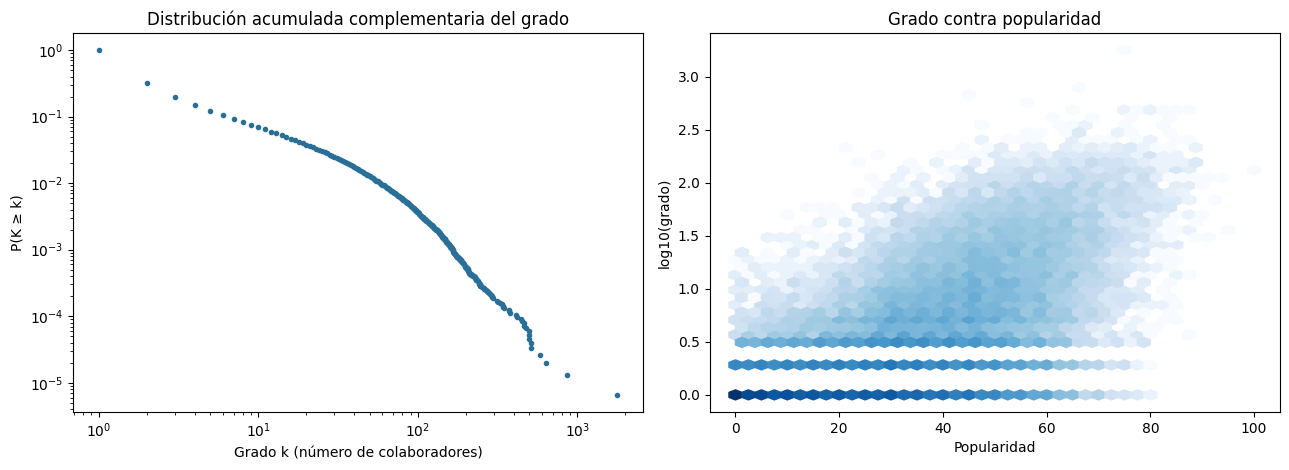

Grado medio: 3.93, mediana: 1, máximo: 1778
Artistas con un solo colaborador: 67.8%


,name,grado,followers,popularity,genres
602,Johann Sebastian Bach,1778,3701532.0,75,"[baroque, classical, early music, german baroque]"
1639,Mc Gw,858,1448741.0,66,"[funk carioca, funk mtg, funk ostentacao, funk..."
20864,MC MN,632,32119.0,46,"[funk carioca, funk mtg]"
8071,Jean Sibelius,579,194098.0,56,"[classical, finnish classical, impressionism, ..."
538,Armin van Buuren,513,4094260.0,74,"[dutch trance, edm, pop dance, progressive hou..."
483,Gucci Mane,509,4454550.0,77,"[atl hip hop, dirty south rap, gangster rap, h..."
606,Steve Aoki,498,3689746.0,74,"[dance pop, edm, electro house, pop dance, pop..."
179,Snoop Dogg,495,8686870.0,84,"[g funk, gangster rap, hip hop, pop rap, rap, ..."
940,Diplo,494,2498486.0,79,"[edm, electro house, moombahton, ninja, pop, p..."
287,Tiësto,475,6497410.0,82,"[big room, brostep, dance pop, dutch edm, edm,..."


In [11]:
grados = nodos['grado'].values
valores, frecuencias = np.unique(grados, return_counts=True)
ccdf = 1 - np.cumsum(frecuencias) / frecuencias.sum() + frecuencias / frecuencias.sum()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

axes[0].loglog(valores, ccdf, marker='.', ls='none', color='#2a6f97')
axes[0].set_xlabel('Grado k (número de colaboradores)')
axes[0].set_ylabel('P(K ≥ k)')
axes[0].set_title('Distribución acumulada complementaria del grado')

axes[1].hexbin(nodos['popularity'], np.log10(nodos['grado']), gridsize=40, bins='log', cmap='Blues')
axes[1].set_xlabel('Popularidad')
axes[1].set_ylabel('log10(grado)')
axes[1].set_title('Grado contra popularidad')

fig.tight_layout()
plt.show()

print(f'Grado medio: {grados.mean():.2f}, mediana: {np.median(grados):.0f}, máximo: {grados.max()}')
print(f'Artistas con un solo colaborador: {(grados == 1).mean():.1%}')
display(nodos.nlargest(10, 'grado')[['name', 'grado', 'followers', 'popularity', 'genres']])

La distribución del grado tiene cola pesada: el 67.8% de los artistas colaboró con un único artista (mediana 1), mientras que un puñado supera los 500 colaboradores. Es el patrón característico de las redes sociales, con muchos nodos periféricos y pocos concentradores.

El grado y la popularidad se relacionan positivamente, aunque con mucha dispersión: hay artistas con un solo colaborador en todo el rango de popularidad. Los artistas con más colaboradores no son los más famosos, sino tres grupos particulares:

* **Compositores clásicos** (Bach, Sibelius): Spotify los acredita como artistas en cada grabación de sus obras, por lo que cada orquesta o intérprete aparece como *"colaborador"*.
* **MCs de funk carioca** (Mc Gw, MC MN): este género brasileño se caracteriza por tener una gran cantidad de colaboraciones entre MCs.
* **DJs/productores de EDM y raperos** (Armin van Buuren, Steve Aoki, Diplo, Gucci Mane, Snoop Dogg), con muchos remixes y *features*.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">3. Transformación</span></div>

 ## Decisiones de transformación

1. **Matriz de adyacencia dispersa:** con alrededor de 150 k nodos, una matriz densa ocuparía demasiado espacio. Representamos el grafo como una matriz dispersa CSR de `scipy`, simétrica porque la colaboración no tiene dirección. Sobre ella implementaremos PageRank y HITS por el método de potencias, que solo requiere productos matriz-vector.
2. **Componentes conexas:** no nos restringimos a la componente gigante. PageRank está bien definido en grafos desconectados gracias a la teletransportación; en HITS, en cambio, el vector principal se concentra en una sola componente, lo cual se verificará más adelante.
3. **Macrogéneros como tópicos:** los géneros de Spotify son demasiado finos (miles de etiquetas) para usarlos directamente como tópicos. Agrupamos los géneros en 10 macrogéneros mediante palabras clave; un artista puede pertenecer a varios macrogéneros a la vez (p. ej. `pop rap` cuenta para *Pop* y para *Hip hop / Rap*).
4. **Versión dirigida para HITS:** en un grafo no dirigido, HITS colapsa en un solo vector (lo demostraremos en la sección 4). Para darle sentido a los papeles de hub y autoridad construimos una versión dirigida orientando cada colaboración del artista **menos popular al más popular** (empates por seguidores). La interpretación es que el artista menor *"apunta"* al mayor al buscar la colaboración. Esta orientación es un supuesto de modelado y no información contenida en los datos.

In [12]:
# Índice entero para cada artista
indice = pd.Series(nodos.index, index=nodos['spotify_id'])
origen = indice[aristas['id_0']].values
destino = indice[aristas['id_1']].values
n = len(nodos)

# Grafo no dirigido: cada colaboración aparece en ambos sentidos
A = sp.csr_matrix((np.ones(2 * len(origen)), (np.r_[origen, destino], np.r_[destino, origen])), shape=(n, n))
print(f'A: {A.shape}, entradas no nulas: {A.nnz:,}, densidad: {A.nnz / n**2:.2e}')
print(f'Simétrica: {(A != A.T).nnz == 0}, Valor máximo: {A.max():.0f}')

A: (152157, 152157), entradas no nulas: 597,934, densidad: 2.58e-05
Simétrica: True, Valor máximo: 1


In [13]:
n_componentes, etiqueta_componente = connected_components(A, directed=False)
tamanos = np.bincount(etiqueta_componente)
nodos['componente'] = etiqueta_componente
gigante = tamanos.argmax()

print(f'Componentes conexas: {n_componentes:,}')
print(f'Componente gigante: {tamanos.max():,} artistas ({tamanos.max() / n:.1%})')
print(f'Siguientes componentes más grandes: {np.sort(tamanos)[-6:-1][::-1].tolist()}')
print(f'Componentes de 2 artistas: {(tamanos == 2).sum():,}')

Componentes conexas: 1,342
Componente gigante: 147,193 artistas (96.7%)
Siguientes componentes más grandes: [66, 37, 22, 21, 21]
Componentes de 2 artistas: 597


In [14]:
macrogeneros = {
    'Hip hop / Rap': ['hip hop', 'rap', 'trap', 'drill', 'grime'],
    'Pop': ['pop'],
    'Electrónica': ['house', 'edm', 'techno', 'trance', 'electro', 'dubstep', 'drum and bass', 'big room', 'hardstyle', 'dance'],
    'Latina': ['latin', 'reggaeton', 'mexican', 'mexicana', 'cumbia', 'bachata', 'salsa', 'banda', 'corrido', 'urbano'],
    'Brasileña': ['brazilian', 'sertanejo', 'funk carioca', 'funk mtg', 'funk ostentacao', 'mpb', 'pagode', 'forro', 'arrocha', 'piseiro', 'brega'],
    'Rock / Metal': ['rock', 'punk', 'metal', 'grunge'],
    'R&B / Soul': ['r&b', 'soul', 'urban contemporary'],
    'Clásica / Soundtrack': ['classical', 'orchestra', 'soundtrack', 'opera', 'baroque', 'compositional', 'choral', 'early music'],
    'Jazz / Blues': ['jazz', 'blues', 'swing', 'bebop'],
    'Country / Folk': ['country', 'folk', 'americana', 'bluegrass', 'singer-songwriter'],
}
topicos = list(macrogeneros)

# Matriz booleana artista x tópico: True si alguno de sus géneros contiene una palabra clave
pertenencia = np.column_stack([
    nodos['genres'].map(lambda lista: any(clave in g for g in lista for clave in claves)).values for claves in macrogeneros.values()
])

cubiertos = pertenencia.any(axis=1)
con_genero = nodos['n_generos'] > 0
print(f'Artistas con algún género: {con_genero.sum():,}')
print(f'Artistas asignados a algún macrogénero: {cubiertos.sum():,} ({cubiertos.sum() / con_genero.sum():.1%} de los que tienen género)')

# Géneros frecuentes que no quedaron en ningún macrogénero, para revisar las palabras clave
sin_asignar = Counter(g for lista, c in zip(nodos['genres'], cubiertos) if not c for g in lista)
print('Géneros frecuentes no asignados:', [g for g, _ in sin_asignar.most_common(15)])

Artistas con algún género: 52,614
Artistas asignados a algún macrogénero: 43,305 (82.3% de los que tienen género)
Géneros frecuentes no asignados: ['filmi', 'opm', 'amapiano', 'russelater', 'sleep', 'modern bollywood', 'tollywood', 'manele', 'drift phonk', 'eurovision', 'mollywood', 'cubaton', 'sky room', 'partyschlager', 'mahraganat']


In [15]:
# Grafo dirigido para HITS: del artista menos popular al más popular (empates por seguidores)
clave_orden = nodos['popularity'].values * 1e9 + nodos['followers'].fillna(0).values
menor_a_mayor = clave_orden[origen] < clave_orden[destino]
print(f'Colaboraciones con empate exacto: {(clave_orden[origen] == clave_orden[destino]).sum()}')

fuente = np.where(menor_a_mayor, origen, destino)
sumidero = np.where(menor_a_mayor, destino, origen)
A_dir = sp.csr_matrix((np.ones(len(fuente)), (fuente, sumidero)), shape=(n, n))

grado_salida = np.asarray(A_dir.sum(axis=1)).ravel()
grado_entrada = np.asarray(A_dir.sum(axis=0)).ravel()
print(f'A_dir: {A_dir.nnz:,} arcos, artistas sin arcos de salida: {(grado_salida == 0).mean():.1%} y sin arcos de entrada: {(grado_entrada == 0).mean():.1%}')

Colaboraciones con empate exacto: 0
A_dir: 298,967 arcos, artistas sin arcos de salida: 3.4% y sin arcos de entrada: 83.6%


## Resultados de transformación

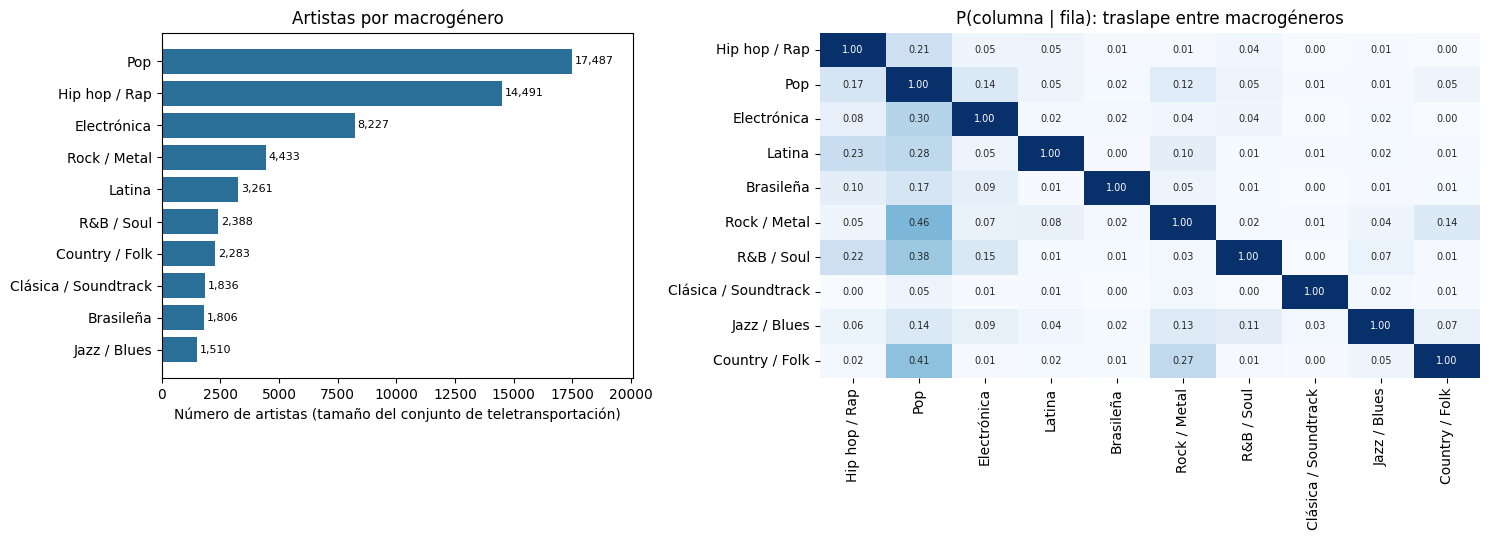

In [16]:
conteo_topicos = pd.Series(pertenencia.sum(axis=0), index=topicos).sort_values()
coocurrencia = pd.DataFrame(pertenencia.T.astype(int) @ pertenencia.astype(int), index=topicos, columns=topicos)
# Proporción de artistas del tópico fila que también pertenecen al tópico columna
proporcion = coocurrencia.div(np.diag(coocurrencia), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [1, 1.4]})
barras = axes[0].barh(conteo_topicos.index, conteo_topicos.values, color='#2a6f97')
axes[0].bar_label(barras, fmt='{:,.0f}', fontsize=8, padding=2)
axes[0].set_xlabel('Número de artistas (tamaño del conjunto de teletransportación)')
axes[0].set_title('Artistas por macrogénero')
axes[0].set_xlim(0, conteo_topicos.max() * 1.15)

sns.heatmap(proporcion, annot=True, fmt='.2f', cmap='Blues', ax=axes[1], cbar=False, annot_kws={'fontsize': 7})
axes[1].set_title('P(columna | fila): traslape entre macrogéneros')
fig.tight_layout()
plt.show()

La red queda representada por una matriz de 152,157 × 152,157 con densidad de $2.6 \times 10^{-5}$, lo que confirma la necesidad del formato disperso. El 96.7% de los artistas pertenece a una sola componente gigante; las otras 1,341 componentes son diminutas (la siguiente tiene 66 artistas y 597 son parejas aisladas).

Los 10 macrogéneros cubren al 82.3% de los artistas con género. Los géneros que quedaron fuera son principalmente regionales (`filmi`, `opm`, `amapiano`, `manele`, ...) y no encajan claramente en ningún macrogénero, por lo que se dejaron sin asignar. Los tópicos son de tamaños muy distintos (de 17,487 artistas en *Pop* a 1,510 en *Jazz / Blues*) y se traslapan: el 46% de los artistas de *Rock / Metal* y el 41% de *Country / Folk* también tienen alguna etiqueta *pop*, y el 23% de los artistas de *Latina* también son de *Hip hop / Rap*. *Clásica / Soundtrack* y *Brasileña* son los macrogéneros más aislados.

En la versión dirigida, el 83.6% de los artistas no recibe ningún arco: casi todos los artistas periféricos colaboran con alguien más popular que ellos.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">4. Aplicación de Algoritmos </span></div>

Las siguientes funciones se usan en las tres técnicas: una tabla con los artistas mejor clasificados según un puntaje, la correlación de Spearman de un puntaje con las variables de popularidad, y el traslape entre los primeros *k* lugares de dos rankings.

In [17]:
def tabla_top(puntaje, k=10, nombre='puntaje'):
    """
    Construye una tabla con los k artistas de mayor puntaje y sus atributos principales.

    Args:
        puntaje (np.ndarray): Puntaje por artista, alineado con el índice de `nodos`.
        k (int, 10 predeterminado): Número de artistas a mostrar.
        nombre (str, 'puntaje' predeterminado): Nombre de la columna del puntaje.

    Returns:
        tabla (pd.DataFrame): Artistas ordenados de mayor a menor puntaje.
    """
    top = np.argsort(-puntaje)[:k]
    tabla = nodos.loc[top, ['name', 'grado', 'followers', 'popularity']].copy()
    tabla['genres'] = nodos.loc[top, 'genres'].map(lambda l: ', '.join(l[:3]))
    tabla[nombre] = puntaje[top]
    tabla.index = range(1, k + 1)
    return tabla


def correlaciones(puntajes):
    """
    Calcula la correlación de Spearman entre cada puntaje y el grado, los seguidores y la
    popularidad de los artistas. Se usa Spearman porque las distribuciones son muy asimétricas
    y solo interesa el orden relativo. Se omiten los artistas con valores faltantes.

    Args:
        puntajes (dict[str, np.ndarray]): Puntajes por artista, con su nombre como llave.

    Returns:
        tabla (pd.DataFrame): Correlaciones, una fila por puntaje.
    """
    referencias = {'Grado': nodos['grado'].values, 'Seguidores': nodos['followers'].values, 'Popularidad': nodos['popularity'].values}
    tabla = {}
    for ref, valores in referencias.items():
        tabla[ref] = {}
        for nombre, p in puntajes.items():
            validos = ~np.isnan(valores) & ~np.isnan(p)
            tabla[ref][nombre] = spearmanr(p[validos], valores[validos])[0]
    return pd.DataFrame(tabla)


def traslape_top(puntaje_a, puntaje_b, k=100):
    """
    Proporción de artistas compartidos entre los k primeros lugares de dos rankings.

    Args:
        puntaje_a, puntaje_b (np.ndarray): Puntajes por artista a comparar.
        k (int, 100 predeterminado): Tamaño del top a comparar.

    Returns:
        float: |top_k(a) ∩ top_k(b)| / k.
    """
    top_a = set(np.argsort(-puntaje_a)[:k])
    top_b = set(np.argsort(-puntaje_b)[:k])
    return len(top_a & top_b) / k

### PageRank

Sea $M$ la matriz de transición estocástica por columnas, $M_{ij} = A_{ij} / d_j$, donde $d_j$ es el grado del artista $j$. PageRank es el vector estacionario de

$$ r = \beta M r + (1 - \beta)\, v, $$

donde $\beta$ es la probabilidad de seguir una colaboración y $v$ es la distribución de teletransportación. En PageRank clásico, $v = \frac{1}{n}\mathbf{1}$. La teletransportación garantiza que la cadena sea irreducible y aperiódica aun con las 1,342 componentes conexas de la red, por lo que existe un único vector estacionario. Si un nodo no tiene salidas (nodo colgante, relevante solo en grafos dirigidos), su masa se redistribuye según $v$.

Implementamos el método de potencias sobre la matriz dispersa. La misma función sirve para PageRank sensible a tópico cambiando $v$.

In [18]:
def pagerank_potencia(A, v=None, beta=0.85, tol=1e-10, max_iter=300):
    """
    Calcula PageRank por el método de potencias sobre una matriz de adyacencia dispersa.

    Args:
        A (sp.csr_matrix): Matriz de adyacencia (A[i, j] = 1 si hay arista de i a j).
        v (np.ndarray, None predeterminado): Vector de teletransportación (no negativo, se normaliza
            a suma 1). Si es None se usa la distribución uniforme (PageRank clásico).
        beta (float, 0.85 predeterminado): Probabilidad de seguir una arista en lugar de teletransportarse.
        tol (float, 1e-10 predeterminado): Criterio de paro sobre la norma L1 entre iteraciones.
        max_iter (int, 300 predeterminado): Número máximo de iteraciones.

    Returns:
        r (np.ndarray): Vector de PageRank (suma 1).
        iteraciones (int): Iteraciones realizadas hasta converger.
    """
    n = A.shape[0]
    grado_salida = np.asarray(A.sum(axis=1)).ravel()
    colgantes = grado_salida == 0
    inverso = np.divide(1.0, grado_salida, out=np.zeros(n), where=~colgantes)
    # M[j, i] = A[i, j] / d_i: matriz estocástica por columnas
    M = A.T.multiply(inverso).tocsr()

    v = np.full(n, 1 / n) if v is None else v / v.sum()
    r = v.copy()
    for iteracion in range(1, max_iter + 1):
        r_nuevo = beta * (M @ r) + (beta * r[colgantes].sum() + 1 - beta) * v
        if np.abs(r_nuevo - r).sum() < tol:
            return r_nuevo, iteracion
        r = r_nuevo
    return r, max_iter

In [19]:
pagerank, iteraciones = pagerank_potencia(A)
nodos['pagerank'] = pagerank
print(f'PageRank convergió en {iteraciones} iteraciones, suma = {pagerank.sum():.6f}')

# Validación de la implementación contra networkx
pagerank_nx = nx.pagerank(nx.from_scipy_sparse_array(A), alpha=0.85, tol=1e-12)
pagerank_nx = np.array([pagerank_nx[i] for i in range(n)])
print(f'Diferencia máxima con networkx: {np.abs(pagerank - pagerank_nx).max():.2e}')

display(tabla_top(pagerank, 15, 'PageRank'))

PageRank convergió en 123 iteraciones, suma = 1.000000
Diferencia máxima con networkx: 3.99e-09


,name,grado,followers,popularity,genres,PageRank
1,Johann Sebastian Bach,1778,3701532.0,75,"baroque, classical, early music",0.004988
2,Jean Sibelius,579,194098.0,56,"classical, finnish classical, impressionism",0.001474
3,Mc Gw,858,1448741.0,66,"funk carioca, funk mtg, funk ostentacao",0.001148
4,הכוכב הבא,377,24901.0,48,,0.000983
5,MC MN,632,32119.0,46,"funk carioca, funk mtg",0.000923
6,John Williams,413,1154733.0,70,"orchestral soundtrack, soundtrack",0.000919
7,A.R. Rahman,463,23828027.0,79,"desi pop, filmi, modern bollywood",0.000741
8,Armin van Buuren,513,4094260.0,74,"dutch trance, edm, pop dance",0.000711
9,Andrea Bocelli,341,2221093.0,67,"classical tenor, italian tenor, operatic pop",0.000679
10,Gucci Mane,509,4454550.0,77,"atl hip hop, dirty south rap, gangster rap",0.000648


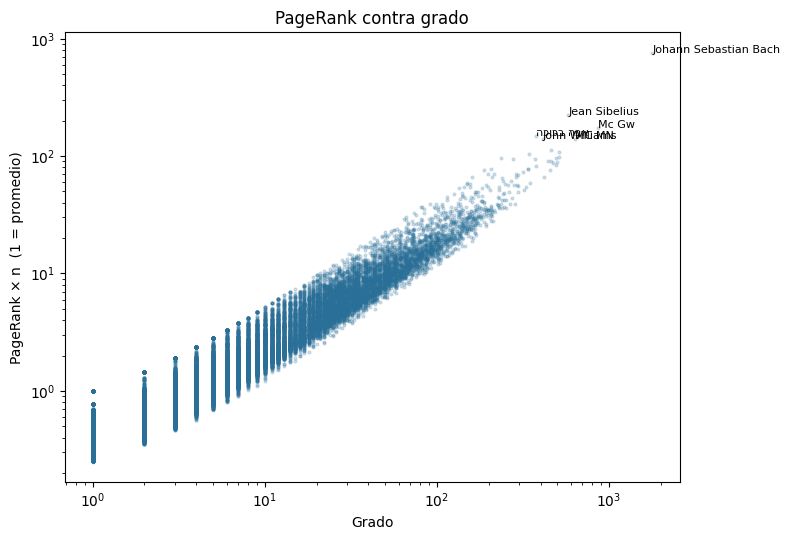

,Grado,Seguidores,Popularidad
PageRank,0.772452,0.405619,0.409905


In [20]:
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(nodos['grado'], pagerank * n, s=4, alpha=0.2, color='#2a6f97')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Grado')
ax.set_ylabel('PageRank × n  (1 = promedio)')
ax.set_title('PageRank contra grado')
for i in np.argsort(-pagerank)[:6]:
    ax.annotate(nodos.loc[i, 'name'], (nodos.loc[i, 'grado'], pagerank[i] * n), fontsize=8)
fig.tight_layout()
plt.show()

display(correlaciones({'PageRank': pagerank}))

Realizaremos un barrido del factor de amortiguamiento $\beta$ para evaluar la estabilidad del ranking.

In [21]:
barrido = []
for beta in [0.5, 0.7, 0.85, 0.9, 0.95, 0.99]:
    r_beta, iteraciones = pagerank_potencia(A, beta=beta, max_iter=2000)
    barrido.append({
        'beta': beta,
        'iteraciones': iteraciones,
        'Spearman vs. β=0.85': spearmanr(r_beta, pagerank)[0],
        'Traslape top 100 vs. β=0.85': traslape_top(r_beta, pagerank, 100),
        'Spearman vs. grado': spearmanr(r_beta, nodos['grado'])[0],
        'Masa del top 100': np.sort(r_beta)[-100:].sum(),
        'Primer lugar': nodos.loc[r_beta.argmax(), 'name'],
    })
display(pd.DataFrame(barrido).set_index('beta').round(3))

,iteraciones,Spearman vs. β=0.85,Traslape top 100 vs. β=0.85,Spearman vs. grado,Masa del top 100,Primer lugar
beta,,,,,,
0.50,31,0.984,0.92,0.727,0.035,Johann Sebastian Bach
0.70,58,0.995,0.94,0.749,0.043,Johann Sebastian Bach
0.85,123,1.000,1.00,0.772,0.047,Johann Sebastian Bach
0.90,187,0.999,0.95,0.783,0.048,Johann Sebastian Bach
0.95,381,0.992,0.88,0.798,0.048,Johann Sebastian Bach
0.99,1937,0.973,0.70,0.805,0.049,Johann Sebastian Bach


**PageRank. Observaciones**

1. *Implementación:* el método de potencias converge en 123 iteraciones y coincide con `networkx` hasta $4 \times 10^{-9}$.

2. *Relación con el grado:* en un grafo no dirigido sin teletransportación, la distribución estacionaria del caminante aleatorio es exactamente $d_i / 2m$, es decir, proporcional al grado. La teletransportación solo corrige parcialmente esta relación, de ahí la correlación de Spearman de 0.77 con el grado, que además crece conforme $\beta \to 1$ (de 0.73 con $\beta = 0.5$ a 0.81 con $\beta = 0.99$). En cambio, la correlación con seguidores y popularidad es de apenas 0.41: ser central en la red de colaboraciones no equivale a ser famoso.

3. *Primeros lugares:* PageRank favorece las estructuras de *estrella*, en las que un nodo concentra muchas hojas que solo colaboran con él y que le transfieren toda su probabilidad. Así aparecen compositores (Bach, Sibelius, John Williams, Ennio Morricone), MCs de funk carioca, el programa de televisión israelí *HaKokhav HaBa* (`הכוכב הבא`, que acredita a sus concursantes) y *Deep Sleep*, un proyecto de música para dormir. Ninguno de los 10 artistas con más seguidores aparece en el top 15.

4. *Sensibilidad a $\beta$:* entre 0.5 y 0.95 el ranking es muy estable (Spearman > 0.98 y traslape del top 100 de al menos 88%). Con $\beta = 0.99$ el traslape baja a 70% y el número de iteraciones se dispara a 1,937, pues la convergencia es del orden de $\beta^k$. Elegir $\beta = 0.85$ resulta un buen equilibrio entre estabilidad y costo.

### HITS

HITS asigna a cada nodo un puntaje de hub $h$ y uno de autoridad $a$, que se refuerzan mutuamente:

$$ a = A^\top h, \qquad h = A a, $$

normalizando en cada paso. Al converger, $a$ es el vector propio principal de $A^\top A$ y $h$ el de $A A^\top$. Si el grafo es no dirigido, $A = A^\top$, ambas matrices son $A^2$ y, por lo tanto, **$h = a$**: hubs y autoridades coinciden, y ambos equivalen a la centralidad de vector propio de $A$. Primero lo comprobamos en el grafo no dirigido y después aplicamos HITS al grafo dirigido por popularidad.

In [22]:
def hits_potencia(A, tol=1e-10, max_iter=1000):
    """
    Calcula los puntajes de hub y autoridad de HITS por el método de potencias.

    Args:
        A (sp.csr_matrix): Matriz de adyacencia (A[i, j] = 1 si hay arista de i a j).
        tol (float, 1e-10 predeterminado): Criterio de paro sobre la norma L1 entre iteraciones de h.
        max_iter (int, 1000 predeterminado): Número máximo de iteraciones.

    Returns:
        h (np.ndarray): Puntajes de hub (norma L2 igual a 1).
        a (np.ndarray): Puntajes de autoridad (norma L2 igual a 1).
        iteraciones (int): Iteraciones realizadas hasta converger.
    """
    n = A.shape[0]
    AT = A.T.tocsr()
    h = np.full(n, 1 / np.sqrt(n))
    for iteracion in range(1, max_iter + 1):
        a = AT @ h
        a /= np.linalg.norm(a)
        h_nuevo = A @ a
        h_nuevo /= np.linalg.norm(h_nuevo)
        if np.abs(h_nuevo - h).sum() < tol:
            return h_nuevo, a, iteracion
        h = h_nuevo
    return h, a, max_iter

In [23]:
hub, autoridad, iteraciones = hits_potencia(A)
print(f'HITS (no dirigido) convergió en {iteraciones} iteraciones')
print(f'Diferencia máxima entre hubs y autoridades: {np.abs(hub - autoridad).max():.2e}')

# Validación contra la centralidad de vector propio (vector principal de A)
_, vector_propio = eigsh(A, k=1, which='LA')
vector_propio = np.abs(vector_propio.ravel())
print(f'Diferencia máxima con el vector propio principal de A: {np.abs(autoridad - vector_propio).max():.2e}')

nodos['hits'] = autoridad
display(tabla_top(autoridad, 15, 'HITS'))

HITS (no dirigido) convergió en 127 iteraciones
Diferencia máxima entre hubs y autoridades: 1.08e-13
Diferencia máxima con el vector propio principal de A: 1.19e-12


,name,grado,followers,popularity,genres,HITS
1,Farruko,284,13975050.0,84,"latin hip hop, reggaeton, trap latino",0.128224
2,French Montana,320,4648251.0,76,"gangster rap, hip hop, pop rap",0.114710
3,Gucci Mane,509,4454550.0,77,"atl hip hop, dirty south rap, gangster rap",0.109495
4,Ty Dolla $ign,252,4339428.0,81,"dance pop, hip hop, pop",0.105858
5,De La Ghetto,193,6242132.0,81,"latin hip hop, reggaeton, reggaeton flow",0.103751
6,Lil Wayne,273,12587804.0,85,"hip hop, new orleans rap, pop rap",0.102234
7,Chris Brown,245,16868785.0,87,"dance pop, pop, r&b",0.102211
8,Snoop Dogg,495,8686870.0,84,"g funk, gangster rap, hip hop",0.100210
9,Arcangel,169,8825949.0,81,"latin hip hop, reggaeton, trap latino",0.099748
10,J Balvin,205,35224872.0,88,"reggaeton, reggaeton colombiano, trap latino",0.099438


,HITS (a²),PageRank
Masa del top 10,0.114,0.013
Masa del top 100,0.556,0.047
Masa del top 1000,0.945,0.176


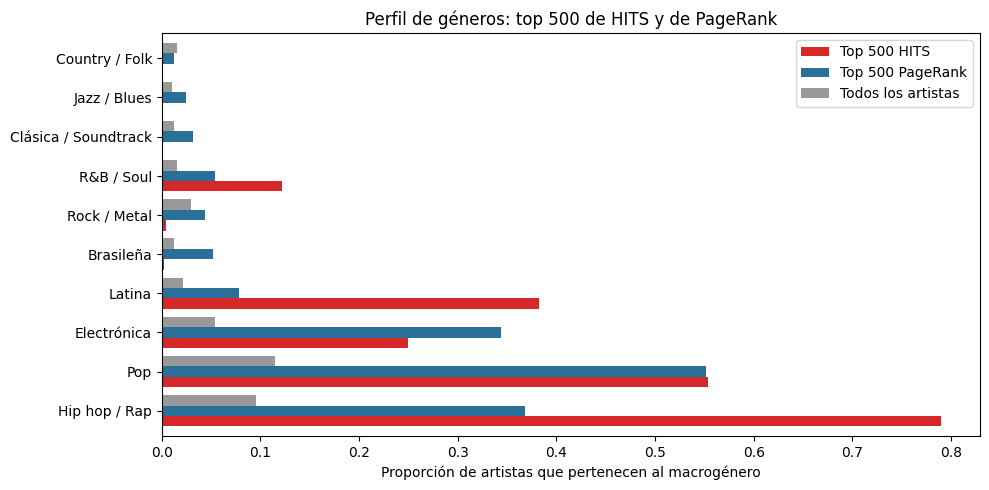

,Grado,Seguidores,Popularidad
PageRank,0.772452,0.405619,0.409905
HITS no dirigido,0.390039,0.246083,0.252287


In [24]:
# ¿Dónde se concentra el puntaje de HITS?
masa = autoridad ** 2  # la norma L2 es 1, así que a_i^2 es la fracción de "masa" de cada artista
top_hits = np.argsort(-autoridad)[:500]
top_pagerank = np.argsort(-pagerank)[:500]

concentracion = pd.DataFrame({
    'HITS (a²)': [masa[np.argsort(-masa)[:k]].sum() for k in (10, 100, 1000)],
    'PageRank': [np.sort(pagerank)[::-1][:k].sum() for k in (10, 100, 1000)],
}, index=['Masa del top 10', 'Masa del top 100', 'Masa del top 1000'])
display(concentracion.round(3))

perfil = pd.DataFrame({
    'Top 500 HITS': pertenencia[top_hits].mean(axis=0),
    'Top 500 PageRank': pertenencia[top_pagerank].mean(axis=0),
    'Todos los artistas': pertenencia.mean(axis=0),
}, index=topicos)

fig, ax = plt.subplots(figsize=(10, 5))
perfil.plot.barh(ax=ax, color=['#d62828', '#2a6f97', '#999999'], width=0.8)
ax.set_xlabel('Proporción de artistas que pertenecen al macrogénero')
ax.set_title('Perfil de géneros: top 500 de HITS y de PageRank')
fig.tight_layout()
plt.show()

display(correlaciones({'PageRank': pagerank, 'HITS no dirigido': autoridad}))

**HITS no dirigido. Observaciones**

1. *Hubs = autoridades:* como se anticipó, la diferencia entre ambos vectores es del orden de $10^{-13}$, y ambos coinciden con el vector propio principal de $A$. En una red no dirigida HITS solo produce una medida, la centralidad de vector propio.

2. *Concentración:* los 100 primeros artistas acumulan el 55.6% de la masa de HITS, frente al 4.7% en PageRank. El top 500 es en un 79% de *Hip hop / Rap* y en un 38% de *Latina*, y no contiene artistas de clásica ni de funk brasileño. HITS identifica un único núcleo denso: el bloque de reggaeton y hip hop estadounidense (Farruko, French Montana, Gucci Mane, J Balvin, Lil Wayne, ...), donde las estrellas colaboran mucho entre sí.

3. *Efecto TKC (tightly-knit community):* el vector propio principal se concentra en la comunidad más densamente conectada, porque es la que tiene el mayor valor propio. Una estrella como Bach, con 1,778 vecinos que son hojas, aporta un valor propio de alrededor de $\sqrt{1778} \approx 42$, menor que el del núcleo de reggaeton y hip hop, donde cada estrella tiene a su vez a muchos vecinos bien conectados. Por eso los artistas que dominan PageRank prácticamente desaparecen en HITS.

In [25]:
hub_dir, autoridad_dir, iteraciones = hits_potencia(A_dir)
nodos['hub_dir'] = hub_dir
nodos['autoridad_dir'] = autoridad_dir
print(f'HITS (dirigido) convergió en {iteraciones} iteraciones')
print(f'Masa (a²) del primer lugar en autoridad: {np.max(autoridad_dir) ** 2:.1%}')

print('Autoridades: artistas buscados por artistas menos populares')
display(tabla_top(autoridad_dir, 12, 'Autoridad'))
print('Hubs: artistas que colaboran con artistas más populares que ellos')
display(tabla_top(hub_dir, 12, 'Hub'))

HITS (dirigido) convergió en 293 iteraciones
Masa (a²) del primer lugar en autoridad: 99.8%
Autoridades: artistas buscados por artistas menos populares


,name,grado,followers,popularity,genres,Autoridad
1,Johann Sebastian Bach,1778,3701532.0,75,"baroque, classical, early music",0.999053
2,Jean Sibelius,579,194098.0,56,"classical, finnish classical, impressionism",0.038088
3,John Williams,413,1154733.0,70,"orchestral soundtrack, soundtrack",0.012946
4,Rolf Zuckowski,72,99690.0,55,"children's music, kindermusik",0.007142
5,Ennio Morricone,275,940452.0,64,"classic soundtrack, italian soundtrack, orches...",0.004911
6,Max Richter,82,795315.0,72,"compositional ambient, post-minimalism",0.003603
7,Hans Zimmer,145,2978307.0,75,"german soundtrack, orchestral soundtrack, soun...",0.003224
8,Andrea Bocelli,341,2221093.0,67,"classical tenor, italian tenor, operatic pop",0.003079
9,Franz Xaver Gruber,81,1364.0,28,,0.002940
10,Wolfgang Amadeus Mozart,11,4658811.0,75,"classical, classical era",0.002936


Hubs: artistas que colaboran con artistas más populares que ellos


,name,grado,followers,popularity,genres,Hub
1,Aled Jones,142,13756.0,33,operatic pop,0.026098
2,Boston Symphony Orchestra,4,53147.0,54,"american orchestra, classical performance, orc...",0.025056
3,Tarja,109,287728.0,45,"gothic metal, gothic symphonic metal, opera metal",0.025020
4,Anne-Sophie Mutter,3,54110.0,45,"classical performance, violin",0.024887
5,Andrew Davis,3,5760.0,50,"choral, orchestral performance",0.024749
6,Royal Concertgebouw Orchestra,3,40967.0,53,"classical performance, orchestra",0.024749
7,Arja Koriseva,30,5943.0,29,"classic finnish pop, classic iskelma, iskelma",0.024706
8,Hilary Hahn,3,132522.0,50,"classical performance, violin",0.024665
9,Anne Sofie von Otter,4,23873.0,39,"choral, classical mezzo-soprano, classical per...",0.024609
10,Jouni Somero,3,336.0,23,nordic classical piano,0.024594


In [26]:
# Contraste: ranking por el número de colaboraciones recibidas (grado de entrada) en el grafo dirigido
nodos['grado_entrada'] = grado_entrada
display(correlaciones({'Autoridad (dirigido)': autoridad_dir, 'Hub (dirigido)': hub_dir,
                       'Grado de entrada': grado_entrada, 'Grado de salida': grado_salida}))
print(f'Spearman entre hub y autoridad: {spearmanr(hub_dir, autoridad_dir)[0]:.3f}')
print(f'Proporción de hubs del top 100 que son vecinos de {nodos.loc[autoridad_dir.argmax(), "name"]}: '
      f'{A_dir[np.argsort(-hub_dir)[:100], autoridad_dir.argmax()].toarray().mean():.0%}')

,Grado,Seguidores,Popularidad
Autoridad (dirigido),0.613738,0.495190,0.511881
Hub (dirigido),0.292486,0.165641,0.197662
Grado de entrada,0.638821,0.518564,0.519170
Grado de salida,0.829971,0.362616,0.384040


Spearman entre hub y autoridad: 0.114
Proporción de hubs del top 100 que son vecinos de Johann Sebastian Bach: 100%


**HITS dirigido. Observaciones**

El efecto TKC se vuelve extremo: Johann Sebastian Bach concentra el 99.8% de la masa de autoridad, y el 100% de los 100 mejores hubs son intérpretes de su obra (Aled Jones, la Sinfónica de Boston, Anne-Sophie Mutter, etcétera). Al orientar las aristas por popularidad, los 1,778 intérpretes, casi todos menos populares que Bach, apuntan hacia él. Así, el valor singular principal de $A$ queda determinado por esta estrella y el resto de la red recibe puntajes prácticamente nulos.

Aunque la correlación de la autoridad con la popularidad (0.51) es mayor que en el caso no dirigido, debe tomarse con cautela, pues la propia orientación de las aristas se construyó con la popularidad. De hecho, el grado de entrada por sí solo alcanza la misma correlación.

Repetimos HITS dirigido sobre el subgrafo que excluye a los artistas del macrogénero *Clásica / Soundtrack*, para observar los papeles de hub y autoridad en el resto de la red. A los artistas excluidos se les asigna `NaN`, de modo que quedan al final de los rankings y fuera de las correlaciones.

In [27]:
fuera_clasica = ~pertenencia[:, topicos.index('Clásica / Soundtrack')]
hub_sub, autoridad_sub, iteraciones = hits_potencia(A_dir[fuera_clasica][:, fuera_clasica])

hub_sin_clasica = np.full(n, np.nan)
autoridad_sin_clasica = np.full(n, np.nan)
hub_sin_clasica[fuera_clasica] = hub_sub
autoridad_sin_clasica[fuera_clasica] = autoridad_sub

print(f'HITS (dirigido, sin clásica) convergió en {iteraciones} iteraciones sobre {fuera_clasica.sum():,} artistas')
print(f'Masa (a²) del primer lugar en autoridad: {np.nanmax(autoridad_sin_clasica) ** 2:.1%} | del top 10: {np.sort(autoridad_sub ** 2)[-10:].sum():.1%}')

print('Autoridades sin el clúster clásico')
display(tabla_top(np.nan_to_num(autoridad_sin_clasica, nan=-1), 12, 'Autoridad'))
print('Hubs sin el clúster clásico')
display(tabla_top(np.nan_to_num(hub_sin_clasica, nan=-1), 12, 'Hub'))
display(correlaciones({'Autoridad (dirigido, sin clásica)': autoridad_sin_clasica, 'Hub (dirigido, sin clásica)': hub_sin_clasica}))
print(f'Spearman entre hub y autoridad: {spearmanr(hub_sub, autoridad_sub)[0]:.3f}')

HITS (dirigido, sin clásica) convergió en 138 iteraciones sobre 150,321 artistas
Masa (a²) del primer lugar en autoridad: 3.5% | del top 10: 23.7%
Autoridades sin el clúster clásico


,name,grado,followers,popularity,genres,Autoridad
1,Farruko,284,13975050.0,84,"latin hip hop, reggaeton, trap latino",0.187712
2,Snoop Dogg,495,8686870.0,84,"g funk, gangster rap, hip hop",0.175979
3,Chris Brown,245,16868785.0,87,"dance pop, pop, r&b",0.162337
4,Lil Wayne,273,12587804.0,85,"hip hop, new orleans rap, pop rap",0.156847
5,Gucci Mane,509,4454550.0,77,"atl hip hop, dirty south rap, gangster rap",0.147159
6,Ty Dolla $ign,252,4339428.0,81,"dance pop, hip hop, pop",0.144845
7,Future,209,12110689.0,88,"atl hip hop, rap, southern hip hop",0.144136
8,Ñengo Flow,266,3686756.0,80,"latin hip hop, reggaeton, reggaeton flow",0.141076
9,Nicky Jam,194,17688765.0,82,"latin hip hop, reggaeton, trap latino",0.135147
10,Myke Towers,146,9487383.0,85,"reggaeton, trap latino",0.134817


Hubs sin el clúster clásico


,name,grado,followers,popularity,genres,Hub
1,French Montana,320,4648251.0,76,"gangster rap, hip hop, pop rap",0.112405
2,Juicy J,194,2891371.0,73,"crunk, dirty south rap, gangster rap",0.093816
3,Yandel,118,6199874.0,75,"latin hip hop, reggaeton, reggaeton flow",0.090712
4,Jeezy,156,2206605.0,69,"atl hip hop, crunk, dirty south rap",0.089970
5,DJ Drama,187,1278173.0,58,"dirty south rap, gangster rap, hip hop",0.089462
6,Gucci Mane,509,4454550.0,77,"atl hip hop, dirty south rap, gangster rap",0.088455
7,Meek Mill,150,6481503.0,75,"hip hop, philly rap, pop rap",0.087533
8,J Alvarez,203,4816928.0,66,"latin hip hop, reggaeton, reggaeton flow",0.085518
9,T.I.,227,4332136.0,73,"atl hip hop, dance pop, dirty south rap",0.085094
10,The Game,295,4165499.0,74,"gangster rap, hip hop, pop rap",0.084579


,Grado,Seguidores,Popularidad
"Autoridad (dirigido, sin clásica)",0.619080,0.495892,0.511620
"Hub (dirigido, sin clásica)",0.361484,0.212893,0.238746


Spearman entre hub y autoridad: 0.151


**HITS dirigido sin el clúster clásico. Observaciones**

Al retirar a los 1,836 artistas de *Clásica / Soundtrack*, la autoridad deja de concentrarse en un solo artista (el primer lugar tiene 3.5% de la masa y el top 10, 23.7%), y los papeles de hub y autoridad se vuelven interpretables:

* **Autoridades:** las estrellas del núcleo de reggaeton y hip hop, buscadas por muchos artistas menos populares que también colaboran con otras estrellas.
* **Hubs:** artistas que colaboran sistemáticamente con artistas más populares que ellos. Destaca DJ Drama (popularidad 58), conocido por presentar *mixtapes* con muchos raperos invitados, junto con French Montana, Juicy J, Jeezy, Meek Mill o Yandel, muy activos como invitados en canciones de otros.

La correlación de Spearman entre hub y autoridad es de solo 0.15, lo que confirma que ahora miden papeles distintos. Sin embargo, HITS sigue concentrándose en el mismo núcleo denso: describe muy bien la élite de la comunidad dominante, pero dice poco del resto de la red.

### PageRank sensible a tópico

En el PageRank sensible a tópico (Haveliwala, 2002), el vector de teletransportación deja de ser uniforme y se concentra en un conjunto $S_t$ de nodos del tópico $t$:

$$ v_t = \frac{1}{|S_t|}\mathbf{1}_{S_t}, \qquad r_t = \beta M r_t + (1 - \beta)\, v_t. $$

El caminante aleatorio, al teletransportarse, siempre reinicia en un artista del macrogénero, por lo que $r_t$ mide la importancia de cada artista *vista desde* ese género. Como $r_t$ es lineal en $v_t$, para un usuario con preferencias $w_t$ sobre varios tópicos basta combinar los vectores precalculados: $r_w = \sum_t w_t\, r_t$.

In [28]:
pagerank_topico = np.column_stack([pagerank_potencia(A, v=pertenencia[:, t].astype(float))[0] for t in range(len(topicos))])

# Top 8 artistas por tópico
top_por_topico = pd.DataFrame({
    topico: nodos.loc[np.argsort(-pagerank_topico[:, t])[:8], 'name'].values
    for t, topico in enumerate(topicos)
}, index=range(1, 9))
display(top_por_topico.T)

,1,2,3,4,5,6,7,8
Hip hop / Rap,Gucci Mane,Mozzy,Fumez The Engineer,Snoop Dogg,Tech N9ne,Waka Flocka Flame,Eko Fresh,The Game
Pop,Raimonds Pauls,Renuka Panwar,Tiësto,Steve Aoki,A.R. Rahman,R3HAB,Diplo,Pritam
Electrónica,Armin van Buuren,Moby,Tiësto,Tritonal,Diplo,Steve Aoki,Roger Shah,Above & Beyond
Latina,Remik Gonzalez,Redimi2,Luis Alfonso Partida El Yaki,Luis R Conriquez,Ñengo Flow,Alex Zurdo,Santa RM,Santa Fe Klan
Brasileña,Mc Gw,MC MN,Mc Delux,Mc Rd,DENNIS,Dj Batata,Elis Regina,Mc Danny
Rock / Metal,Johann Sebastian Bach,Jimmy Barnes,HEALTH,Pappo,TobyMac,Bi-2,Dolly Parton,Tarja
R&B / Soul,Snoop Dogg,Incognito,Eric Bellinger,Gucci Mane,Black Coffee,James Brown,Diplo,The Roots
Clásica / Soundtrack,Johann Sebastian Bach,Jean Sibelius,John Williams,Iceland Symphony Orchestra,Andrea Bocelli,Ennio Morricone,Adolphe Adam,Rolf Zuckowski
Jazz / Blues,Louis Armstrong,Bing Crosby,John Williams,Ella Fitzgerald,Nils Landgren,Ceylan Ertem,Frank Sinatra,B.B. King
Country / Folk,Dolly Parton,Nashville Cast,Johnny Cash,The Dubliners,MC Stojan,Jelly Roll,Rasta,Mercedes Sosa


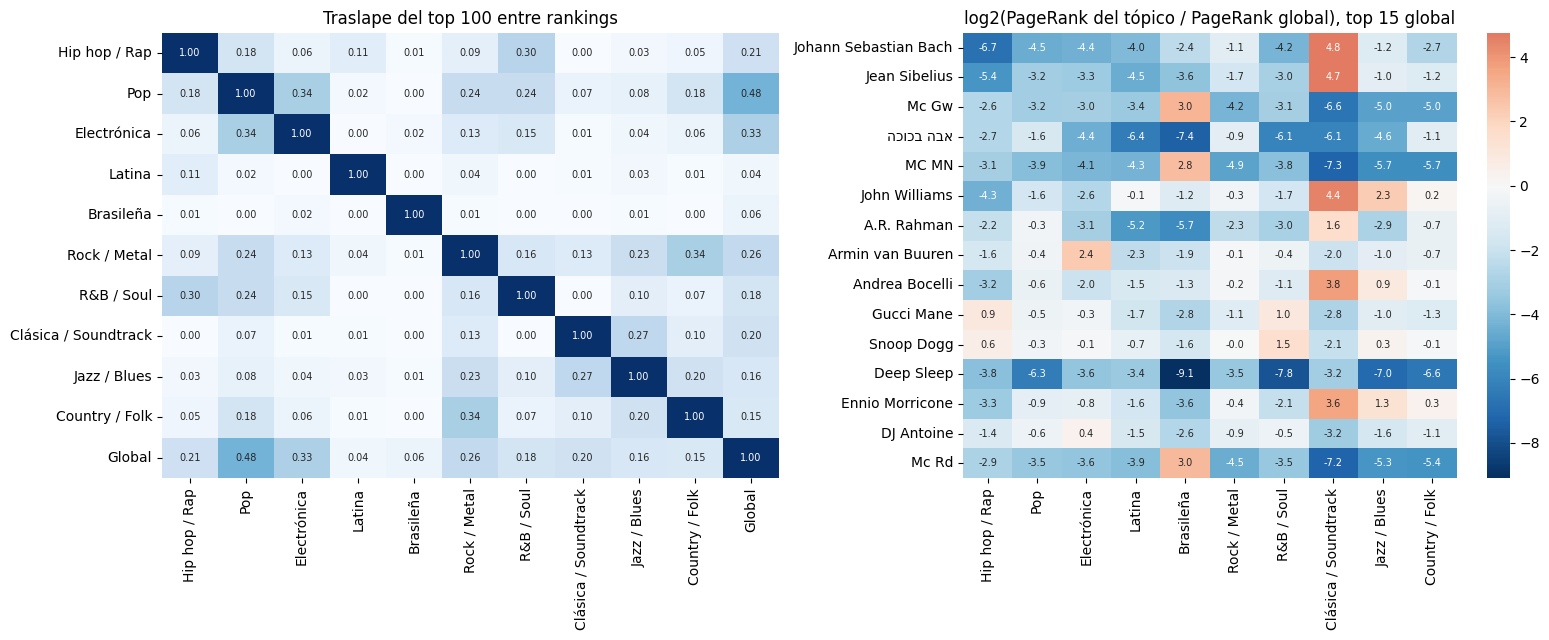

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

# Traslape del top 100 entre tópicos y con el PageRank global
rankings = {**{t: pagerank_topico[:, i] for i, t in enumerate(topicos)}, 'Global': pagerank}
traslapes = pd.DataFrame({a: {b: traslape_top(ra, rb, 100) for b, rb in rankings.items()} for a, ra in rankings.items()})
sns.heatmap(traslapes, annot=True, fmt='.2f', cmap='Blues', ax=axes[0], cbar=False, annot_kws={'fontsize': 7})
axes[0].set_title('Traslape del top 100 entre rankings')

# Afinidad de los 15 artistas con mayor PageRank global con cada tópico: log2(r_t / r_global)
top_global = np.argsort(-pagerank)[:15]
afinidad = pd.DataFrame(np.log2(pagerank_topico[top_global] / pagerank[top_global, None]),
                        index=nodos.loc[top_global, 'name'], columns=topicos)
sns.heatmap(afinidad, annot=True, fmt='.1f', cmap='RdBu_r', center=0, ax=axes[1], annot_kws={'fontsize': 7})
axes[1].set_title('log2(PageRank del tópico / PageRank global), top 15 global')
axes[1].set_ylabel('')

fig.tight_layout()
plt.show()

In [30]:
# Pureza: proporción del top 100 de cada tópico que pertenece al macrogénero, contra su proporción en la red
pureza = pd.DataFrame({
    'Proporción en la red': pertenencia.mean(axis=0),
    'Top 100 PageRank global': pertenencia[np.argsort(-pagerank)[:100]].mean(axis=0),
    'Top 100 PageRank del tópico': [pertenencia[np.argsort(-pagerank_topico[:, t])[:100], t].mean() for t in range(len(topicos))],
    'Top 100 sin género asignado': [(~cubiertos[np.argsort(-pagerank_topico[:, t])[:100]]).mean() for t in range(len(topicos))],
}, index=topicos)
display(pureza.round(3))

,Proporción en la red,Top 100 PageRank global,Top 100 PageRank del tópico,Top 100 sin género asignado
Hip hop / Rap,0.095,0.28,0.96,0.01
Pop,0.115,0.58,0.90,0.05
Electrónica,0.054,0.35,0.94,0.05
Latina,0.021,0.04,0.99,0.00
Brasileña,0.012,0.06,0.91,0.05
Rock / Metal,0.029,0.03,0.51,0.09
R&B / Soul,0.016,0.00,0.51,0.03
Clásica / Soundtrack,0.012,0.10,0.51,0.16
Jazz / Blues,0.010,0.02,0.56,0.13
Country / Folk,0.015,0.00,0.59,0.09


Por último, comprobamos la propiedad de linealidad con un usuario hipotético cuyas preferencias son 70% música latina y 30% hip hop / rap.

In [31]:
pesos = {'Latina': 0.7, 'Hip hop / Rap': 0.3}

# Combinación lineal de los vectores ya calculados
r_combinado = sum(w * pagerank_topico[:, topicos.index(t)] for t, w in pesos.items())

# PageRank calculado directamente con la teletransportación combinada
v_usuario = sum(w * pertenencia[:, topicos.index(t)] / pertenencia[:, topicos.index(t)].sum() for t, w in pesos.items())
r_directo, _ = pagerank_potencia(A, v=v_usuario)

print(f'Diferencia máxima entre la combinación lineal y el cálculo directo: {np.abs(r_combinado - r_directo).max():.2e}')
display(tabla_top(r_combinado, 10, 'PageRank 70% Latina, 30% Hip hop'))

Diferencia máxima entre la combinación lineal y el cálculo directo: 3.68e-12


,name,grado,followers,popularity,genres,"PageRank 70% Latina, 30% Hip hop"
1,Remik Gonzalez,84,930908.0,58,"latin hip hop, mexican hip hop",0.001614
2,Redimi2,109,1870745.0,63,"latin christian, latin worship, rap conciencia",0.001501
3,Santa RM,112,551339.0,58,"latin hip hop, mexican hip hop",0.001392
4,Ñengo Flow,266,3686756.0,80,"latin hip hop, reggaeton, reggaeton flow",0.001380
5,Alex Zurdo,87,1336082.0,64,"latin christian, rap cristiano, reggaeton cris...",0.001350
6,Luis Alfonso Partida El Yaki,71,182278.0,66,"musica mexicana, nueva musica mexicana, sierreno",0.001343
7,Santa Fe Klan,107,6250507.0,78,mexican hip hop,0.001335
8,Luis R Conriquez,61,1255540.0,82,"corrido, nueva musica mexicana",0.001323
9,Aleman,116,4091128.0,74,"mexican hip hop, trap mexicano",0.001194
10,Gera MX,100,3528221.0,77,"mexican hip hop, rap conciencia",0.001107


**PageRank sensible a tópico. Observaciones**

1. *Rankings por tópico:* cada tópico recupera figuras reconocibles de su género: Louis Armstrong, Bing Crosby y Ella Fitzgerald en *Jazz / Blues*; Dolly Parton y Johnny Cash en *Country / Folk*; Armin van Buuren, Moby y Tiësto en *Electrónica*; Mc Gw y Elis Regina en *Brasileña*. El tópico *Latina* queda dominado por la comunidad de hip hop mexicano y rap cristiano (Remik Gonzalez, Redimi2, Santa Fe Klan), que es más densa y cerrada que la del reggaeton comercial. En *Pop*, la palabra clave `pop` captura muchos pops regionales (`latvian pop`, `haryanvi pop`), así que el tópico es heterogéneo y aparecen Raimonds Pauls o Renuka Panwar en los primeros lugares. Bach encabeza también *Rock / Metal*, probablemente porque bandas de metal sinfónico y artistas de rock que graban obras clásicas lo acreditan (p. ej. Tarja, que también aparece en el top 8).

2. *Pureza:* en *Hip hop / Rap*, *Pop*, *Electrónica*, *Latina* y *Brasileña*, entre el 90% y el 99% del top 100 pertenece al tópico. En los macrogéneros pequeños y muy conectados con otros (*Rock / Metal*, *R&B / Soul*, *Clásica*, *Jazz*, *Country*) la pureza baja a alrededor del 55%, porque el caminante sale del tópico con facilidad. El PageRank sensible a tópico rescata géneros invisibles en el ranking global: en el top 100 global solo el 4% es de música latina y ningún artista es de *R&B / Soul* o *Country / Folk*.

3. *Relación entre tópicos:* *Latina* y *Brasileña* comparten como máximo el 11% de su top 100 con cualquier otro ranking, por lo que se trata de comunidades casi autónomas. Los pares más cercanos son *Rock / Metal* – *Country / Folk* (0.34), *Pop* – *Electrónica* (0.34), *Hip hop* – *R&B* (0.30) y *Clásica* – *Jazz* (0.27). El ranking global se parece más al de *Pop* (0.48).

4. *Afinidad de los artistas globales:* la razón $r_t / r$ ubica a cada artista en su contexto: Bach y Sibelius multiplican su PageRank por $2^{4.8}$ en *Clásica*, Mc Gw por $2^{3}$ en *Brasileña* y Armin van Buuren por $2^{2.4}$ en *Electrónica*. *Deep Sleep* y *HaKokhav HaBa*, en cambio, son negativos en todos los tópicos: su PageRank global proviene de comunidades propias, sin géneros asignados, y el PageRank sensible a tópico los descarta.

5. *Linealidad:* la combinación 70/30 de los vectores precalculados coincide con el cálculo directo hasta $4 \times 10^{-12}$. En la práctica, esto permite precalcular un vector por tópico y personalizar el ranking de cualquier usuario sin volver a ejecutar PageRank.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">5. Validación y comparación </span></div>

Si el PageRank de un tópico mide la cercanía de cada artista con ese género, el tópico con mayor puntaje debería coincidir con el género real del artista. Para evaluarlo sin fuga de información, ocultamos el 20% de los artistas con macrogénero (los quitamos de los conjuntos de teletransportación), recalculamos los 10 vectores y predecimos para cada artista oculto el tópico $\arg\max_t r_t$. Como cada $r_t$ suma 1, comparar los puntajes directamente equivale a comparar las afinidades relativas $r_t / r_{global}$. Se considera acierto si el tópico predicho está entre los macrogéneros del artista.

In [32]:
rng = np.random.default_rng(42)
con_topico = np.where(cubiertos)[0]
ocultos = rng.choice(con_topico, size=int(0.2 * len(con_topico)), replace=False)

pertenencia_entreno = pertenencia.copy()
pertenencia_entreno[ocultos] = False
pagerank_topico_entreno = np.column_stack([pagerank_potencia(A, v=pertenencia_entreno[:, t].astype(float))[0] for t in range(len(topicos))])

prediccion = pagerank_topico_entreno[ocultos].argmax(axis=1)
aciertos = pertenencia[ocultos, prediccion]

# Línea base: predecir siempre el macrogénero más frecuente del conjunto de entrenamiento
mas_frecuente = pertenencia_entreno.sum(axis=0).argmax()
linea_base = pertenencia[ocultos, mas_frecuente].mean()
# Línea base por grafo: el macrogénero más frecuente entre los vecinos conocidos (sin caminatas)
votos_vecinos = A[ocultos] @ pertenencia_entreno.astype(float)
tiene_vecinos_conocidos = votos_vecinos.sum(axis=1) > 0
aciertos_vecinos = pertenencia[ocultos, votos_vecinos.argmax(axis=1)] & tiene_vecinos_conocidos

print(f'Artistas ocultos: {len(ocultos):,}')
print(f'Exactitud PageRank sensible a tópico: {aciertos.mean():.1%}')
print(f'Exactitud voto de vecinos directos: {aciertos_vecinos.mean():.1%} '
      f'({(~tiene_vecinos_conocidos).mean():.1%} de los ocultos no tiene vecinos con género conocido)')
print(f'Línea base (siempre {topicos[mas_frecuente]}): {linea_base:.1%}')
print(f'Exactitud PageRank sensible a tópico en artistas sin vecinos con género conocido: {aciertos[~tiene_vecinos_conocidos].mean():.1%}')
print(f'Exactitud de ambos métodos en artistas con vecinos con género conocido: '
      f'PageRank por tópico {aciertos[tiene_vecinos_conocidos].mean():.1%},  vecinos {aciertos_vecinos[tiene_vecinos_conocidos].mean():.1%}')

Artistas ocultos: 8,661
Exactitud PageRank sensible a tópico: 60.5%
Exactitud voto de vecinos directos: 60.8% (14.0% de los ocultos no tiene vecinos con género conocido)
Línea base (siempre Pop): 40.3%
Exactitud PageRank sensible a tópico en artistas sin vecinos con género conocido: 45.5%
Exactitud de ambos métodos en artistas con vecinos con género conocido: PageRank por tópico 63.0%,  vecinos 70.7%


In [33]:
por_topico = pd.DataFrame({
    'Artistas ocultos del tópico': pertenencia[ocultos].sum(axis=0),
    'Predichos como el tópico': np.bincount(prediccion, minlength=len(topicos)),
    'Precisión': [aciertos[prediccion == t].mean() if (prediccion == t).any() else np.nan for t in range(len(topicos))],
    'Exhaustividad': [(prediccion[pertenencia[ocultos, t]] == t).mean() for t in range(len(topicos))],
}, index=topicos)
display(por_topico.round(3))

,Artistas ocultos del tópico,Predichos como el tópico,Precisión,Exhaustividad
Hip hop / Rap,2921,1856,0.812,0.516
Pop,3488,785,0.810,0.182
Electrónica,1651,1483,0.703,0.632
Latina,635,905,0.633,0.902
Brasileña,375,506,0.702,0.947
Rock / Metal,910,526,0.416,0.241
R&B / Soul,468,1032,0.264,0.581
Clásica / Soundtrack,342,442,0.654,0.845
Jazz / Blues,291,489,0.288,0.485
Country / Folk,470,637,0.325,0.440


El mismo procedimiento permite proponer un macrogénero para los artistas que Spotify dejó sin etiqueta, usando los vectores calculados con todos los artistas etiquetados:

In [34]:
sin_etiqueta = np.where(nodos['n_generos'].values == 0)[0]
topico_propuesto = pagerank_topico[sin_etiqueta].argmax(axis=1)
# Afinidad del tópico propuesto respecto al PageRank global: qué tan marcada es la preferencia
afinidad_propuesta = pagerank_topico[sin_etiqueta, topico_propuesto] / pagerank[sin_etiqueta]

propuestas = nodos.loc[sin_etiqueta, ['name', 'grado', 'popularity']].copy()
propuestas['macrogénero propuesto'] = np.array(topicos)[topico_propuesto]
propuestas['afinidad (r_t / r)'] = afinidad_propuesta

print(f'Artistas sin género: {len(sin_etiqueta):,}')
display(propuestas['macrogénero propuesto'].value_counts().to_frame('artistas'))
display(propuestas.sort_values('grado', ascending=False).head(10))

Artistas sin género: 99,543


,artistas
macrogénero propuesto,
Hip hop / Rap,20863
Electrónica,18937
Latina,11288
Pop,11137
R&B / Soul,9874
Brasileña,6826
Rock / Metal,5714
Clásica / Soundtrack,5261
Country / Folk,5188


,name,grado,popularity,macrogénero propuesto,afinidad (r_t / r)
23330,הכוכב הבא,377,48,Rock / Metal,0.523345
36024,Nicola Fasano,184,49,Electrónica,1.978811
44852,MC Yuri,141,45,Brasileña,8.963145
13099,Mc Denny,135,48,Brasileña,8.013670
3633,Sofi Tukker,131,68,Electrónica,3.334989
40340,James Curd,114,32,Electrónica,4.025011
34838,Maneiro Na Voz,107,26,Brasileña,7.200795
34954,Diego Miranda,102,33,Electrónica,2.031496
41159,Vetkuk,94,30,R&B / Soul,3.086143
27551,Spada,91,48,Electrónica,2.591413


**Validación. Observaciones**

El PageRank sensible a tópico predice correctamente el macrogénero del 60.5% de los artistas ocultos, frente a 40.3% de la línea base (predecir siempre *Pop*). Sin embargo, no supera a una regla más simple: el voto de los vecinos directos acierta el 60.8% en total y el 70.7% entre los artistas con algún vecino etiquetado, contra 63.0% del PageRank sensible a tópico. Su ventaja real está en el 14% de artistas sin vecinos etiquetados: ahí el voto de vecinos no puede decidir, mientras que las caminatas de varios pasos aún aciertan el 45.5%.

La tabla por tópico muestra un sesgo hacia los tópicos pequeños: como $v_t$ reparte la teletransportación entre $|S_t|$ artistas, cada artista de un tópico pequeño recibe más masa. Por eso se sobrepredicen *R&B / Soul* (1,032 predicciones para 468 casos reales, con precisión de 0.26), *Jazz* y *Country*, mientras que *Pop*, el tópico más grande, apenas se recupera (exhaustividad de 0.18). Normalizar por el tamaño del tópico o calibrar un umbral por clase son mejoras naturales.

Para los 99,543 artistas sin género, la afinidad $r_t / r$ indica qué tan confiable es la propuesta: valores altos (Mc Yuri y Mc Denny en *Brasileña*, con afinidad de 8 a 9) son asignaciones claras, mientras que valores cercanos o menores a 1 (como *HaKokhav HaBa*, con 0.52) indican que el artista no pertenece a ninguno de los 10 macrogéneros.

### Comparación entre medidas

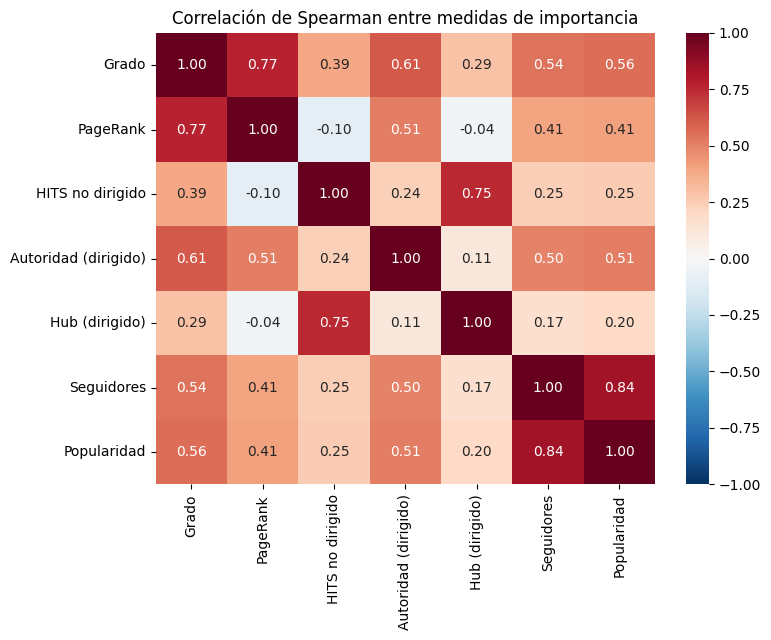

,Grado,PageRank,HITS no dirigido,Autoridad (dirigido),Seguidores,Popularidad,Autoridad (sin clásica)
1,Johann Sebastian Bach,Johann Sebastian Bach,Farruko,Johann Sebastian Bach,Ed Sheeran,Bad Bunny,Farruko
2,Mc Gw,Jean Sibelius,French Montana,Jean Sibelius,Ariana Grande,Drake,Snoop Dogg
3,MC MN,Mc Gw,Gucci Mane,John Williams,Billie Eilish,Taylor Swift,Chris Brown
4,Jean Sibelius,הכוכב הבא,Ty Dolla $ign,Rolf Zuckowski,Drake,The Weeknd,Lil Wayne
5,Armin van Buuren,MC MN,De La Ghetto,Ennio Morricone,Justin Bieber,Kanye West,Gucci Mane
6,Gucci Mane,John Williams,Lil Wayne,Max Richter,Eminem,BTS,Ty Dolla $ign
7,Steve Aoki,A.R. Rahman,Chris Brown,Hans Zimmer,Taylor Swift,Justin Bieber,Future
8,Snoop Dogg,Armin van Buuren,Snoop Dogg,Andrea Bocelli,Arijit Singh,Ed Sheeran,Ñengo Flow
9,Diplo,Andrea Bocelli,Arcangel,Franz Xaver Gruber,Bad Bunny,Eminem,Nicky Jam
10,Tiësto,Gucci Mane,J Balvin,Wolfgang Amadeus Mozart,BTS,Rauw Alejandro,Myke Towers


In [35]:
medidas = {
    'Grado': nodos['grado'].values.astype(float),
    'PageRank': pagerank,
    'HITS no dirigido': autoridad,
    'Autoridad (dirigido)': autoridad_dir,
    'Hub (dirigido)': hub_dir,
    'Seguidores': nodos['followers'].fillna(0).values,
    'Popularidad': nodos['popularity'].values.astype(float),
}
correlacion_medidas = pd.DataFrame(spearmanr(np.column_stack(list(medidas.values())))[0], index=medidas, columns=medidas)

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(correlacion_medidas, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title('Correlación de Spearman entre medidas de importancia')
fig.tight_layout()
plt.show()

medidas_top = {**medidas, 'Autoridad (sin clásica)': np.nan_to_num(autoridad_sin_clasica, nan=-1)}
comparacion = pd.DataFrame({nombre: nodos.loc[np.argsort(-valores)[:10], 'name'].values
                            for nombre, valores in medidas_top.items() if nombre != 'Hub (dirigido)'},
                           index=range(1, 11))
display(comparacion)

Todas las medidas basadas en enlaces tienen una correlación de 0.56 o menos con la popularidad, y ningún artista del top 10 de seguidores o de popularidad aparece en el top 10 de alguna de ellas. La posición en la red de colaboraciones mide algo distinto a la fama: qué tan conectado está un artista y con quién.

La correlación entre PageRank y HITS no dirigido es incluso ligeramente negativa (-0.10). Esto se debe probablemente a la periferia, donde está el 68% de los artistas con un solo colaborador: en HITS, una hoja conectada a una estrella del núcleo recibe un puntaje alto; en PageRank, esa misma hoja recibe muy poco, porque la estrella reparte su probabilidad entre cientos de vecinos. Ambos algoritmos coinciden en señalar a unos cuantos artistas centrales, pero ordenan a la periferia de forma opuesta.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">6. Conclusiones </span></div>

Cada uno de los algoritmos responde una pregunta distinta sobre la red, por lo cual la elección depende de qué se entienda por *"importancia"*.

PageRank es robusto, converge rápido y está bien definido aun en una red con más de mil componentes conexas. Sin embargo, en un grafo no dirigido su resultado está muy ligado al grado, y premia las estructuras de estrella: compositores acreditados en cientos de grabaciones, programas de televisión o proyectos de música funcional, cuya centralidad es en buena medida un artefacto de la forma en que Spotify acredita a los artistas.

HITS, en cambio, colapsa en un solo vector (la centralidad de vector propio) cuando la red no tiene dirección. Además, sufre el efecto TKC: se concentra por completo en la comunidad más densa, ya sea el núcleo de reggaeton y hip hop en la red no dirigida o la estrella de Bach en la dirigida. Solo al orientar las aristas y retirar el clúster clásico, hubs y autoridades adquieren un significado útil (artistas invitados frente a estrellas), aunque a costa de un supuesto de modelado fuerte y siempre limitado a la élite de una comunidad.

El PageRank sensible a tópico resultó el más informativo para esta red. Rescata comunidades que el ranking global ignora (música latina, R&B, country), descarta nodos centrales sin relación con ningún género y, por su linealidad, permite personalizar los rankings sin recalcular. Como clasificador de géneros es razonable (60.5% de aciertos contra 40.3% de la línea base), pero no supera al voto de vecinos directos cuando estos existen y está sesgado hacia los tópicos pequeños.

### **Limitaciones**

Los resultados dependen de decisiones de preprocesamiento: la lista de seudoartistas, las palabras clave de los macrogéneros (en particular, el tópico *Pop* es demasiado amplio) y la orientación por popularidad del grafo dirigido. Además, el 65% de los artistas no tiene género, y la cobertura de *charts* parece reflejar la recolección de los datos más que el tamaño de cada mercado.

En resumen, la red de colaboraciones de Spotify no es una sola jerarquía, sino un conjunto de comunidades por género con estructuras muy distintas. Un análisis por tópico describe mejor esa estructura que cualquier ranking global.